<a href="https://colab.research.google.com/github/beabritw/CampanhasMarketing/blob/main/AnaliseComunidades.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# ==============================================================================
# --- INSTALAÇÃO E IMPORTACAO DE BIBLIOTECAS ---
# ==============================================================================

!pip install pyvis
!pip install python-louvain

import networkx as nx
import matplotlib.pyplot as plt
from pyvis.network import Network
#import community as co
import community.community_louvain as community_louvain
import math
from collections import deque

In [2]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 1. Centralidade de Grau ---
# ==============================================================================

"""
mede a popularidade de um nó, contando quantas conexões diretas ele tem
"""

def calcular_centralidade_de_grau(G):
    """
    Fórmula = grauNó(v) / (NumVertices-1)
    """
    centrality = {}
    num_nodes = len(G.nodes())
    if num_nodes <= 1:
        return {node: 1 for node in G.nodes()}

    for node in G.nodes():
        degree = G.degree(node)
        centrality[node] = degree / (num_nodes - 1)
    return centrality

In [3]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 2. Algoritmo busca em largura (bfs) (p/ calcular centralidade de proximidade) ---
# ==============================================================================

"""
usa bfs como função interna pra calcular a funcao de proximidade e pra restringir o nó para visualizacao
"""

def bfs_caminho_mais_curto(G, inicio):
    """
    encontra o caminho mais curto de um nó de início para todos os outros.
    retorna um dicionário de {nó: distância}.
    """
    if inicio not in G:
        return {}

    distancias = {inicio: 0} # para armazenar as distâncias
    fila = deque([inicio])

    while fila:
        no_atual = fila.popleft()

        for vizinho in G.neighbors(no_atual):
            if vizinho not in distancias:
                distancias[vizinho] = distancias[no_atual] + 1
                fila.append(vizinho)

    return distancias

In [4]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 3. Centralidade de Proximidade ---
# ==============================================================================

"""
Mede a rapidez com que um nó alcança todos os outros
Vertices com taxa alta proximidade são os que espalham informação mais rápido por toda a rede
*com normalizacao*
"""

def calcular_centralidade_de_proximidade(G):
    """
    Fórmula = (N-1) / sum(d(v, u) for u in V)
    obs.: d(v, u) é a distância do caminho mais curto entre v e u.
    """
    centrality = {}
    num_nodes = len(G.nodes())

    for node in G.nodes():
        # usa implementação de BFS
        shortest_paths = bfs_caminho_mais_curto(G, node)
        # --------------------------------

        total_distance = sum(shortest_paths.values())

        num_reachable = len(shortest_paths)

        if total_distance == 0 or num_reachable == 1:
            centrality[node] = 0.0
        else:
            centrality[node] = (num_reachable - 1.0) / total_distance


    return centrality

In [5]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 4. Centralidade de Intermediação ---
# ==============================================================================


"""
mede o quanto um nó atua como ponte
"""

def calcular_centralidade_de_intermediacao(G):
    """
    Fórmula = sum_{s!=v!=t} (sigma_st(v) / sigma_st)
    Onde sigma_st é o número total de caminhos mais curtos de s a t,
    e sigma_st(v) é o número desses caminhos que passam por v.
    """
    centrality = {node: 0.0 for node in G.nodes()}

    for s in G.nodes():
        for t in G.nodes():
            if s == t:
                continue

            # encontra todos os caminhos mais curtos entre s e t
            all_shortest_paths = list(nx.all_shortest_paths(G, source=s, target=t))

            if not all_shortest_paths:
                continue

            num_shortest_paths = len(all_shortest_paths)

            for path in all_shortest_paths:
                for intermediary_node in path[1:-1]:
                    centrality[intermediary_node] += 1 / num_shortest_paths

 # normalização para grafos não direcionados
    num_nodes = len(G.nodes())
    if num_nodes > 2:
        scale = 1.0 / ((num_nodes - 1) * (num_nodes - 2))
        for node in centrality:
            centrality[node] *= scale
            centrality[node] /= 2.0   # corrige a dupla contagem

    return centrality

In [6]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 6. Cálculo do PageRank ---
# ==============================================================================

"""
mede a influência real de um vertice
"""

def calcular_pagerank(G, alpha=0.85, max_iter=100, tol=1.0e-6):
    num_nodes = len(G.nodes())
    if num_nodes == 0:
        return {}

    dangling_nodes = [node for node in G.nodes() if G.degree(node) == 0]

    pagerank = {node: 1.0 / num_nodes for node in G.nodes()}

    for _ in range(max_iter):
        last_pagerank = pagerank
        pagerank = {node: 0.0 for node in G.nodes()}

        # soma o PageRank dos vertices pendentes da iteração anterior
        dangling_sum = alpha * sum(last_pagerank[node] for node in dangling_nodes) / num_nodes

        # distribui
        for node in G.nodes():
            # cada nó recebe uma parte dos "dangling nodes"
            pagerank[node] += dangling_sum

            # adiciona a parte que vem dos seus vizinhos (incoming links)
            for neighbor in G.neighbors(node):
                pagerank[node] += alpha * last_pagerank[neighbor] / G.degree(neighbor)

        # fator de teletransporte (aleatório) pra evitar panelinha
        for node in G.nodes():
             pagerank[node] += (1.0 - alpha) / num_nodes

        total_change = sum(abs(pagerank[node] - last_pagerank[node]) for node in G.nodes())
        if total_change < num_nodes * tol:
            return pagerank

    return pagerank

In [7]:
# ==============================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 7. Algoritmo de Girvan Newman ---
# ==============================================================================

# A perfomance desse algoritmo tem complexidade O(E²V), então será tesada apenas no grafo de teste

"""
Encontra comunidades de forma "divisiva": ele vai cortando as arestas que conectam os grupos até que eles se separem.
"""

def girvan_newman_manual(G):
    """
    a cada passo, remove a aresta com a maior centralidade de intermediação de aresta.
    """
    # cópia do grafo, pra remover as arestas
    G_copy = G.copy()

    while G_copy.number_of_edges() > 0:
        # usa a função pronta do nx para esta parte, pois o cálculo manual da intermediação de aresta é um subproblema complexo por si só.
        edge_betweenness = nx.edge_betweenness_centrality(G_copy)

        # encontra a aresta com o valor máximo
        max_edge = max(edge_betweenness, key=edge_betweenness.get)

        G_copy.remove_edge(*max_edge)

        # gera as comunidades (componentes conectados) atuais
        yield tuple(sorted(c) for c in nx.connected_components(G_copy))

In [8]:
# ===========================================================================================
# --- IMPLEMENTAÇÃO DAS FUNÇÕES - 8. BNF para visualizacao parcial do grafo ---
# ===========================================================================================

def restringir_rede_por_bfs(G, no_inicial, profundidade_max=2):
    """
    cria uma sub-rede a partir de um nó de origem,
    explorando até o nível definido.

    retorna um subgrafo contendo apenas os nós visitados.
    """
    if no_inicial not in G:
        raise ValueError(f"O nó {no_inicial} não existe no grafo.")

    visitados = set([no_inicial])
    fila = deque([(no_inicial, 0)])

    while fila:
        atual, nivel = fila.popleft()
        if nivel < profundidade_max:
            for vizinho in G.neighbors(atual):
                if vizinho not in visitados:
                    visitados.add(vizinho)
                    fila.append((vizinho, nivel + 1))

    subgrafo = G.subgraph(visitados).copy()
    print(f"Sub-rede gerada: {len(subgrafo.nodes())} nós, {len(subgrafo.edges())} arestas.")
    return subgrafo



Calculando centralidades...
Cálculos concluídos.

Partição de comunidades (Girvan-Newman):
{0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 0, 22: 0, 23: 0, 24: 0, 25: 0, 26: 0, 27: 0, 28: 0, 29: 0, 30: 0, 31: 0, 32: 0, 33: 0}




--- Análise Geral dos Resultados da Rede ---


Nós mais influentes por Centralidade de Grau:
[(33, 0.5151515151515151), (0, 0.48484848484848486), (32, 0.36363636363636365), (2, 0.30303030303030304), (1, 0.2727272727272727)]

Nós mais influentes por PageRank:
[(33, 0.10091791674871212), (0, 0.09700181758983707), (32, 0.07169213006588289), (2, 0.05707842304763673), (1, 0.052878391037427)]

Nós com maior intermediação:
[(0, 0.21881764069263882), (33, 0.15203748797498806), (32, 0.07262355699855681), (2, 0.07182840307840298), (31, 0.06913780663780664)]

Partição de comunidades (Louvain):
{0: 0, 1: 0, 2: 0, 3: 0, 4: 2, 5: 2, 6: 2, 7: 0, 8: 3, 9: 3, 10: 2, 11: 0, 12: 0, 13: 

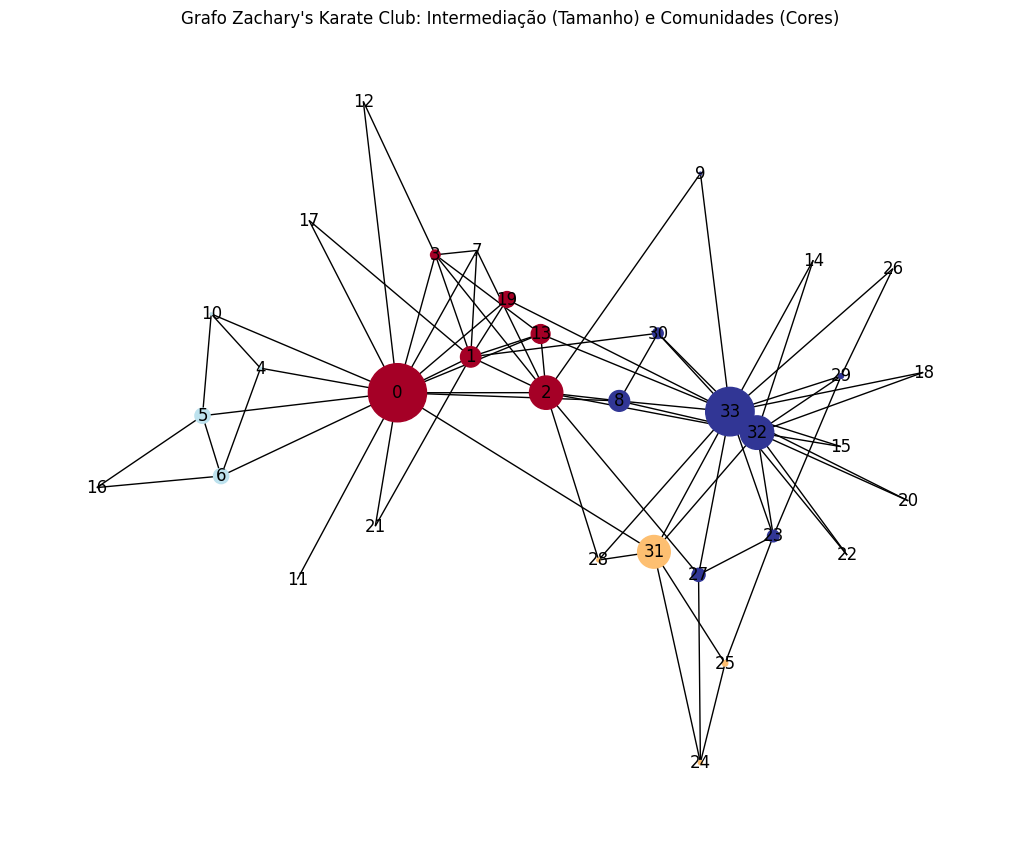

In [13]:
# ==============================================================================
# --- PARTE 1: ANÁLISE DA REDE TESTE (ZACHARY'S KARATE CLUB) ---
# ==============================================================================

# importacao do dataset de comparacao (zachary's karate club)
G = nx.karate_club_graph()

print("Calculando centralidades...")
degree_centrality = calcular_centralidade_de_grau(G)
closeness_centrality = calcular_centralidade_de_proximidade(G)
betweenness_centrality = calcular_centralidade_de_intermediacao(G)
pagerank_centrality = calcular_pagerank(G)
print("Cálculos concluídos.")


for node in G.nodes():
    G.nodes[node]['degree_centrality'] = degree_centrality[node]
    G.nodes[node]['closeness_centrality'] = closeness_centrality[node]
    G.nodes[node]['betweenness_centrality'] = betweenness_centrality[node]
    G.nodes[node]['pagerank_centrality'] = pagerank_centrality[node]


"""
metodo de Louvain: Encontra comunidades rapidamente juntando os nós em grupos para tentar criar a melhor divisão possível.
"""
partition = community_louvain.best_partition(G)
for node in G.nodes():
    G.nodes[node]['community'] = partition[node]


communities_generator = girvan_newman_manual(G)
communities_gn = next(communities_generator)
print("\nPartição de comunidades (Girvan-Newman):")
gn_partition = {}
for i, comm in enumerate(communities_gn):
    for node in comm:
        gn_partition[node] = i
print(gn_partition)

print("\n")


# ==============================================================================
# --- ANÁLISE DOS RESULTADOS ---
# ==============================================================================

print("\n\n" + "="*80)
print("--- Análise Geral dos Resultados da Rede ---")
print("="*80 + "\n")

print("\nNós mais influentes por Centralidade de Grau:")
print(sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True)[:5])

print("\nNós mais influentes por PageRank:")
print(sorted(pagerank_centrality.items(), key=lambda item: item[1], reverse=True)[:5])

print("\nNós com maior intermediação:")
print(sorted(betweenness_centrality.items(), key=lambda item: item[1], reverse=True)[:5])

print("\nPartição de comunidades (Louvain):")
print(partition)


print("\n")

net = Network(notebook=True, height="750px", width="100%", bgcolor="#222222", font_color="white", cdn_resources='remote')
net.barnes_hut()

for node in G.nodes():
    size = G.nodes[node]['degree_centrality'] * 30 + 10
    title = (f"Node: {node}<br>"
             f"Club: {'Mr. Hi' if G.nodes[node]['club'] == 'Mr. Hi' else 'Officer'}<br>"
             f"Community (Louvain): {G.nodes[node]['community']}<br>"
             f"Degree Centrality: {G.nodes[node]['degree_centrality']:.3f}<br>"
             f"Closeness Centrality: {G.nodes[node]['closeness_centrality']:.3f}<br>"
             f"Betweenness Centrality: {G.nodes[node]['betweenness_centrality']:.3f}<br>"
             f"PageRank: {G.nodes[node]['pagerank_centrality']:.3f}")

    # mapeia o ID da comunidade para uma cor
    color_val = G.nodes[node]['community'] / max(partition.values())
    color = plt.cm.RdYlBu(color_val)
    hex_color = '#%02x%02x%02x' % (int(color[0]*255), int(color[1]*255), int(color[2]*255))

    net.add_node(node, label=str(node), title=title, size=size, color=hex_color)


for edge in G.edges():
    net.add_edge(edge[0], edge[1])


# html de visualizacao interativa do grafo
net.show('karate_club_interactive.html')
print("Visualização interativa 'karate_club_interactive.html' foi gerada.")


plt.figure(figsize=(10, 8))
node_size = [v * 8000 for v in betweenness_centrality.values()]
nx.draw_spring(G, node_size=node_size, node_color=list(partition.values()), with_labels=True, cmap=plt.cm.RdYlBu)
plt.title('Grafo Zachary\'s Karate Club: Intermediação (Tamanho) e Comunidades (Cores)')
plt.savefig('karate_club_static.png')






INICIANDO PARTE 2: ANÁLISE DO DATASET DO FACEBOOK

Carregando o grafo do dataset a partir do arquivo 'facebook_combined.txt'...
Grafo 'facebook_combined.txt' carregado com sucesso: 4039 nós e 88234 arestas.

Calculando PageRank global...
Nó mais influente (maior PageRank): 3437

Extraindo sub-rede com BFS a partir do nó 3437 (profundidade 2)...
Sub-rede gerada: 703 nós, 6886 arestas.
Sub-rede criada com 703 nós e 6886 arestas.


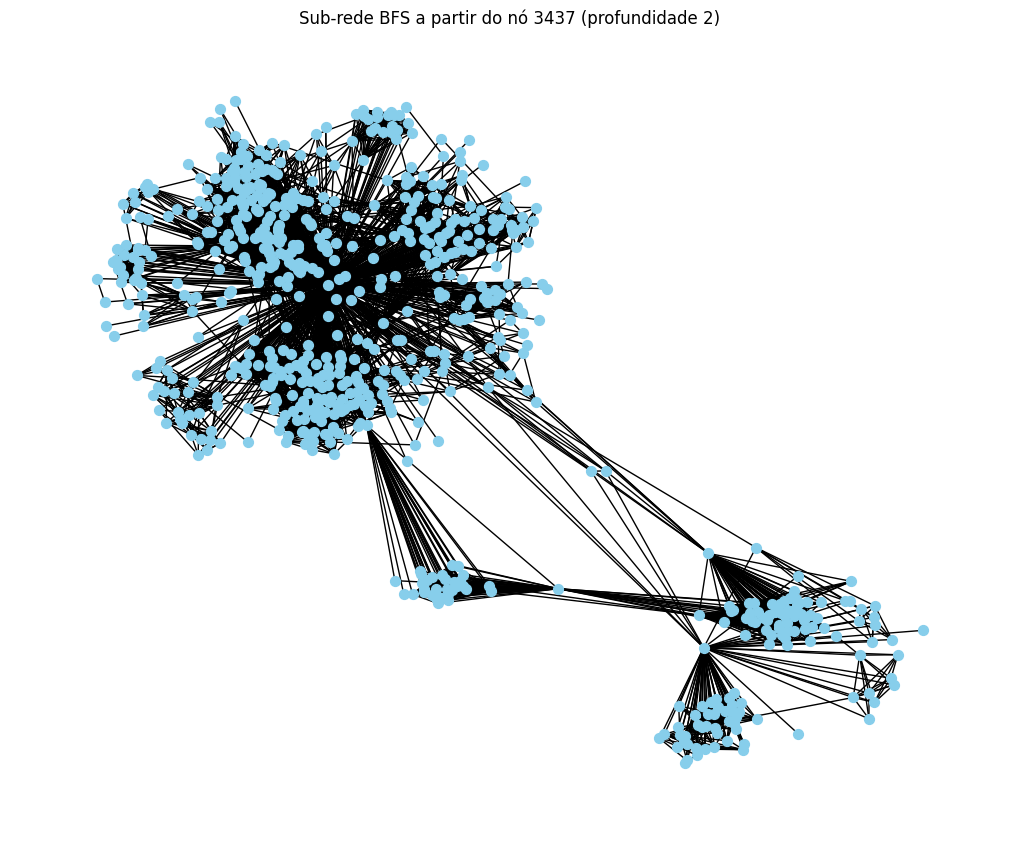


--- Calculando Métricas para a Rede ---
Calculando Centralidade de Grau (manual)...
Calculando PageRank (manual)...
Calculando Centralidade de Proximidade (otimizada)...
Calculando Centralidade de Intermediação (otimizada e aproximada)...
Métricas de centralidade calculadas.

Detectando comunidades com o Método de Louvain...
Detecção concluída. Encontradas 10 comunidades.

Identificando alvos estratégicos para campanha de marketing...
   - Alvo de Maior Alcance: Vertice 3437
   - Alvo de Maior Conector: Vertice 3437
   - Alvo de Maior Influência: Vertice 3437


--- Análise Geral dos Resultados da Rede ---

Total de comunidades (segmentos de mercado) encontradas: 10

Principais 'Hubs' (Top 5 por Centralidade de Grau):
[('3437', 0.7792022792022792), ('3830', 0.15384615384615385), ('3596', 0.1225071225071225), ('3545', 0.11823361823361823), ('3938', 0.11823361823361823)]

Principais 'Pontes' (Top 5 por Centralidade de Intermediação):
[('3437', 0.83427131909306), ('698', 0.204584923036115

In [14]:
# ==============================================================================
# --- PARTE 2: ANÁLISE TEMÁTICA COM DADOS REAIS (EGO-FACEBOOK) ---
# ==============================================================================

print("\n\n" + "="*80)
print("INICIANDO PARTE 2: ANÁLISE DO DATASET DO FACEBOOK")
print("="*80 + "\n")

try:
    arquivo = 'facebook_combined.txt'
    print(f"Carregando o grafo do dataset a partir do arquivo '{arquivo}'...")
    G_fb = nx.read_edgelist(arquivo)
    print(f"Grafo '{arquivo}' carregado com sucesso: {len(G_fb.nodes())} nós e {len(G_fb.edges())} arestas.")


    print("\nCalculando PageRank global...")
    pagerank_centrality_fb = nx.pagerank(G_fb)

    # nó mais influente
    influenciador = max(pagerank_centrality_fb, key=pagerank_centrality_fb.get)
    print(f"Nó mais influente (maior PageRank): {influenciador}")

    # restringir a rede a partir do influenciador principal
    profundidade = 2
    print(f"\nExtraindo sub-rede com BFS a partir do nó {influenciador} (profundidade {profundidade})...")
    G_fb = restringir_rede_por_bfs(G_fb, influenciador, profundidade)
    print(f"Sub-rede criada com {len(G_fb.nodes())} nós e {len(G_fb.edges())} arestas.")

    plt.figure(figsize=(10, 8))
    nx.draw_spring(G_fb, node_size=50, with_labels=False, node_color="skyblue")
    plt.title(f"Sub-rede BFS a partir do nó {influenciador} (profundidade {profundidade})")
    plt.show()

    print("\n--- Calculando Métricas para a Rede ---")

    print("Calculando Centralidade de Grau (manual)...")
    degree_centrality_fb = calcular_centralidade_de_grau(G_fb)

    print("Calculando PageRank (manual)...")
    pagerank_centrality_fb = calcular_pagerank(G_fb)

    # métricas lentas com funções otimizadas do NetworkX
    print("Calculando Centralidade de Proximidade (otimizada)...")
    closeness_centrality_fb = nx.closeness_centrality(G_fb)

    print("Calculando Centralidade de Intermediação (otimizada e aproximada)...")
    k_sample = int(len(G_fb.nodes()) * 0.1)
    betweenness_centrality_fb = nx.betweenness_centrality(G_fb, k=k_sample, normalized=True)

    print("Métricas de centralidade calculadas.")


    # detecção de comunidades
    print("\nDetectando comunidades com o Método de Louvain...")
    partition_fb = community_louvain.best_partition(G_fb)
    num_communities_fb = len(set(partition_fb.values()))
    print(f"Detecção concluída. Encontradas {num_communities_fb} comunidades.")


    print("\nIdentificando alvos estratégicos para campanha de marketing...")
    id_maior_alcance = max(degree_centrality_fb, key=degree_centrality_fb.get)
    id_maior_conector = max(betweenness_centrality_fb, key=betweenness_centrality_fb.get)
    id_maior_influencia = max(pagerank_centrality_fb, key=pagerank_centrality_fb.get)
    print(f"   - Alvo de Maior Alcance: Vertice {id_maior_alcance}")
    print(f"   - Alvo de Maior Conector: Vertice {id_maior_conector}")
    print(f"   - Alvo de Maior Influência: Vertice {id_maior_influencia}")


    print("\n\n" + "="*80)
    print("--- Análise Geral dos Resultados da Rede ---")
    print("="*80 + "\n")

    print(f"Total de comunidades (segmentos de mercado) encontradas: {num_communities_fb}")

    print("\nPrincipais 'Hubs' (Top 5 por Centralidade de Grau):")
    print(sorted(degree_centrality_fb.items(), key=lambda item: item[1], reverse=True)[:5])

    print("\nPrincipais 'Pontes' (Top 5 por Centralidade de Intermediação):")
    print(sorted(betweenness_centrality_fb.items(), key=lambda item: item[1], reverse=True)[:5])

    print("\nPrincipais 'Influenciadores' (Top 5 por PageRank):")
    print(sorted(pagerank_centrality_fb.items(), key=lambda item: item[1], reverse=True)[:5])


    # para gephi
    print("\nAdicionando atributos calculados aos nós do grafo...")
    for node in G_fb.nodes():
        G_fb.nodes[node]['degree_centrality'] = degree_centrality_fb.get(node, 0)
        G_fb.nodes[node]['closeness_centrality'] = closeness_centrality_fb.get(node, 0)
        G_fb.nodes[node]['betweenness_centrality'] = betweenness_centrality_fb.get(node, 0)
        G_fb.nodes[node]['pagerank_centrality'] = pagerank_centrality_fb.get(node, 0)
        G_fb.nodes[node]['community'] = partition_fb.get(node, 0)

    print(f"\nExportando grafo '{arquivo}' com métricas para o Gephi...")
    nx.write_gexf(G_fb, "facebook_network_com_metricas.gexf")
    print("Grafo exportado para 'facebook_network_com_metricas.gexf'. Este arquivo contém o grafo e todas as métricas calculadas. Importe-o no Gephi para criar a visualização final do projeto.")

except FileNotFoundError:
    print(f"\nERRO: Arquivo '{arquivo}' não encontrado.")
    print("Por favor, baixe o dataset de 'https://snap.stanford.edu/data/ego-Facebook.html',")
    print(f"descompacte-o e coloque o arquivo '{arquivo}' na mesma pasta que este script.")

print("Nós da sub-rede:", list(G_fb.nodes())[:10], "...")


print("\n\nAnálise completa.")

In [15]:
# ==============================================================================
# --- PARTE 3: ANÁLISE ESTRATÉGICA PARA CAMPANHA DE MARKETING ---
# ==============================================================================

if 'G_fb' in locals():
    print("\n\n" + "="*90)
    print("ANÁLISE ESTRATÉGICA PARA CAMPANHA DE MARKETING")
    print("="*90 + "\n")

    # --------------------------------------------------------------------------
    # 1. Influenciadores Globais: Alcance, Conexão e Influência Geral
    # --------------------------------------------------------------------------
    print("1️⃣  Influenciadores Globais (para alcance amplo e viralização)\n")
    print(f"   • Maior Alcance Geral (Centralidade de Grau): Nó {id_maior_alcance}")
    print(f"   • Maior Conector Geral (Centralidade de Intermediação): Nó {id_maior_conector}")
    print(f"   • Maior Influência Geral (PageRank): Nó {id_maior_influencia}")
    print("-" * 90)

    # --------------------------------------------------------------------------
    # 2. Influenciador de Nicho: Validação e Confiança no Segmento Principal
    # --------------------------------------------------------------------------
    print("\n2️⃣  Influenciador de Nicho (para validação e confiança em um segmento)\n")

    from collections import Counter
    community_sizes = Counter(partition_fb.values())
    id_maior_comunidade, tamanho_maior_comunidade = community_sizes.most_common(1)[0]

    print(f"   • Maior comunidade identificada: ID {id_maior_comunidade}")
    print(f"   • Tamanho da comunidade: {tamanho_maior_comunidade} membros")


    membros_da_comunidade = [
        node for node, comm_id in partition_fb.items()
        if comm_id == id_maior_comunidade
    ]
    pagerank_da_comunidade = {
        node: pagerank_centrality_fb[node] for node in membros_da_comunidade
    }

    id_validador_local = max(pagerank_da_comunidade, key=pagerank_da_comunidade.get)
    print(f"   • Validador de Nicho (Maior Influência dentro da comunidade {id_maior_comunidade}): Nó {id_validador_local}")
    print("-" * 90)

    # --------------------------------------------------------------------------
    # 3. Estratégia Integrada de Divulgação
    # --------------------------------------------------------------------------
    print("\n3️⃣  Estratégia Integrada de Lançamento Sugerida\n")

    print(f"   🔹 FASE 1 (Confiança Local):")
    print(f"      Ativar o *Validador de Nicho* ({id_validador_local}) para gerar credibilidade no principal segmento de mercado.\n")

    print(f"   🔹 FASE 2 (Reconhecimento Amplo):")
    print(f"      Engajar o *Validador Global* ({id_maior_influencia}) para consolidar a imagem da marca em toda a rede.\n")

    print(f"   🔹 FASE 3 (Viralização Orgânica):")
    print(f"      Mobilizar a *Ponte* ({id_maior_conector}) para conectar comunidades e espalhar a mensagem de forma transversal.\n")

    print(f"   🔹 FASE 4 (Alcance Máximo):")
    print(f"      Utilizar o *Megafone* ({id_maior_alcance}) para impulsionar campanhas e anúncios de grande escala.\n")

    print("="*90)
    print("Conclusão: A sequência de ativação otimiza confiança, validação, difusão e penetração de mercado.")
    print("="*90 + "\n")

else:
    print("\n[ERRO] O grafo 'G_fb' não foi encontrado no ambiente. Execute a Parte 2 antes desta análise.")




ANÁLISE ESTRATÉGICA PARA CAMPANHA DE MARKETING

1️⃣  Influenciadores Globais (para alcance amplo e viralização)

   • Maior Alcance Geral (Centralidade de Grau): Nó 3437
   • Maior Conector Geral (Centralidade de Intermediação): Nó 3437
   • Maior Influência Geral (PageRank): Nó 3437
------------------------------------------------------------------------------------------

2️⃣  Influenciador de Nicho (para validação e confiança em um segmento)

   • Maior comunidade identificada: ID 0
   • Tamanho da comunidade: 153 membros
   • Validador de Nicho (Maior Influência dentro da comunidade 0): Nó 3830
------------------------------------------------------------------------------------------

3️⃣  Estratégia Integrada de Lançamento Sugerida

   🔹 FASE 1 (Confiança Local):
      Ativar o *Validador de Nicho* (3830) para gerar credibilidade no principal segmento de mercado.

   🔹 FASE 2 (Reconhecimento Amplo):
      Engajar o *Validador Global* (3437) para consolidar a imagem da marca em t